In [1]:
# =============================================================================
# 01 - DATA QUALITY AUDIT: EAGLE-I outages + NOAA Storm Events (2014-2025)
# Summary of results lives in reports/01_data_audit_summary.md
# data/ is read-only. Working copies go to work/, small result tables to reports/audit_tables/
# =============================================================================

In [2]:
# ---- 0. Setup ---------------------------------------------------------------
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 120)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
WORK = ROOT / "work"
TABLES = ROOT / "reports" / "audit_tables"
WORK.mkdir(exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

# Inputs: the local file when it is in the repo, otherwise streamed from the Hugging Face dataset
HF_DATASET = "hf://datasets/DSCI-Capstone/county-outage-data"


def src(rel):
    """Local path if the file is in the repo, otherwise its hf:// URL."""
    local = ROOT / rel
    return local.as_posix() if local.exists() else f"{HF_DATASET}/{rel}"

# The two big CSVs are stored as Parquet on Hugging Face (every column still text). The CSV is used when present.
EAGLEI_CSV = DATA / "02_combined" / "eaglei_outages_2014_2025.csv"
STORMS_CSV = DATA / "02_combined" / "storm_events_details_all_years.csv"
EAGLEI_PARQUET = src("data/02_combined/eaglei_outages") + "/*/*.parquet"
STORMS_PARQUET = src("data/02_combined/storm_events_details_all_years.parquet")
CENSUS_CSV = src("data/01_raw/census_counties/co-est2023-alldata.csv")
CROSSWALK = src("data/reference/nws_zone_county_versions.parquet")
MCC_CSV = src("data/reference/eaglei_archive/MCC.csv")
DQI_CSV = src("data/reference/eaglei_archive/DQI.csv")
COVERAGE_CSV = src("data/reference/eaglei_archive/coverage_history.csv")

NULL_CUTOFF = 50  # % null above which a column becomes a drop candidate

# The 13 GB CSV is too big for pandas, so we load it once into a DuckDB file.
# Every column is read as text so we can see the raw values before typing them.
con = duckdb.connect(str(WORK / "audit.duckdb"))

try:  # the dataset is private: streaming uses the token saved by `hf auth login` (not stored in any file here)
    con.execute("CREATE SECRET hf (TYPE huggingface, PROVIDER credential_chain)")
except duckdb.IOException:
    print("No Hugging Face login found. Files not in the repo can't be streamed until you run `hf auth login`.")


def q(sql):
    """Run a SQL query and return a pandas DataFrame."""
    return con.execute(sql).df()


tables = set(q("SHOW TABLES")["name"])
if "eaglei_raw" not in tables:  # takes ~2 minutes the first time
    if EAGLEI_CSV.exists():
        con.execute(f"CREATE TABLE eaglei_raw AS SELECT * FROM read_csv('{EAGLEI_CSV.as_posix()}', all_varchar=true)")
    else:  # hive_partitioning off so SOURCE_YEAR stays text, as in the CSV
        con.execute(f"CREATE TABLE eaglei_raw AS SELECT * FROM read_parquet('{EAGLEI_PARQUET}', hive_partitioning=false)")
if "storms_raw" not in tables:
    if STORMS_CSV.exists():
        con.execute(f"CREATE TABLE storms_raw AS SELECT * FROM read_csv('{STORMS_CSV.as_posix()}', all_varchar=true)")
    else:
        con.execute(f"CREATE TABLE storms_raw AS SELECT * FROM read_parquet('{STORMS_PARQUET}')")

In [3]:
# ---- 0b. Reference tables: Census counties, MCC customers, FEMA regions ----
# Census county list (SUMLEV 050 = county rows). FIPS = 2-digit state + 3-digit county.
census = pd.read_csv(CENSUS_CSV, dtype=str, encoding="latin-1",
                     usecols=["SUMLEV", "STATE", "COUNTY", "STNAME", "CTYNAME", "POPESTIMATE2023"])
census = census[census["SUMLEV"] == "050"].copy()
census["fips"] = census["STATE"] + census["COUNTY"]
census["pop2023"] = census["POPESTIMATE2023"].astype(int)
census = census[["fips", "STNAME", "CTYNAME", "pop2023"]]

# MCC = EAGLE-I's "modeled customer count" per county (the denominator for % out)
mcc = pd.read_csv(MCC_CSV, dtype=str, encoding="utf-8-sig")
mcc["fips"] = mcc["County_FIPS"].str.zfill(5)
mcc["mcc_customers"] = mcc["Customers"].astype(int)
mcc = mcc[["fips", "mcc_customers"]]

# NWS zone -> county crosswalk (one row per zone/county pair per NWS file version)
crosswalk = pd.read_parquet(CROSSWALK)
# The oldest version starts 2014-10-07; let it also cover Jan-Sep 2014
first_version = crosswalk["effective_date"] == crosswalk["effective_date"].min()
crosswalk.loc[first_version, "effective_date"] = pd.Timestamp("2014-01-01").date()

# State FIPS -> postal code, taken from the crosswalk itself (no hand-typed list)
state_abbr = (crosswalk[crosswalk["state"] != ""]
              .assign(state_fips=lambda d: d["county_fips"].str[:2])
              .groupby("state_fips")["state"].agg(lambda s: s.mode()[0]))

# FEMA regions (same grouping EAGLE-I uses for its Data Quality Index).
# Region IV is our "Southeast".
FEMA = {
    1: ["CT", "ME", "MA", "NH", "RI", "VT"], 2: ["NJ", "NY", "PR", "VI"],
    3: ["DE", "MD", "PA", "VA", "DC", "WV"], 4: ["AL", "FL", "GA", "KY", "MS", "NC", "SC", "TN"],
    5: ["IL", "IN", "MI", "MN", "OH", "WI"], 6: ["AR", "LA", "NM", "OK", "TX"],
    7: ["IA", "KS", "MO", "NE"], 8: ["CO", "MT", "ND", "SD", "UT", "WY"],
    9: ["AZ", "CA", "HI", "NV", "GU", "AS", "MP"], 10: ["AK", "ID", "OR", "WA"],
}
abbr_to_region = {a: r for r, states in FEMA.items() for a in states}
regions = pd.DataFrame({"state_fips": state_abbr.index, "abbr": state_abbr.values})
regions["fema_region"] = regions["abbr"].map(abbr_to_region).astype("Int64")
regions["is_southeast"] = regions["fema_region"] == 4

# Register the small tables so SQL can join to them
for name, df in {"census": census, "mcc": mcc, "crosswalk": crosswalk, "regions": regions}.items():
    con.register(name, df)

print(len(census), "Census counties |", len(mcc), "MCC counties |", len(crosswalk), "crosswalk rows")
regions.head()

3144 Census counties | 3234 MCC counties | 104453 crosswalk rows


,state_fips,abbr,fema_region,is_southeast
0,01,AL,4,True
1,02,AK,10,False
2,04,AZ,9,False
3,05,AR,6,False
4,06,CA,9,False


In [4]:
# =============================================================================
# 1. EAGLE-I OUTAGES
# =============================================================================
# ---- 1a. Shape, columns and a sample -----------------------------------------
print(q("SELECT count(*) AS rows FROM eaglei_raw"))
print(q("DESCRIBE eaglei_raw")[["column_name", "column_type"]])
q("SELECT * FROM eaglei_raw USING SAMPLE 5 ROWS")

        rows
0  249316543
       column_name column_type
0      SOURCE_YEAR     VARCHAR
1        fips_code     VARCHAR
2           county     VARCHAR
3            state     VARCHAR
4    customers_out     VARCHAR
5   run_start_time     VARCHAR
6  total_customers     VARCHAR


,SOURCE_YEAR,fips_code,county,state,customers_out,run_start_time,total_customers
0,2014,25021,Norfolk,Massachusetts,16,2014-11-01 05:00:00,None
1,2014,17167,Sangamon,Illinois,1,2014-11-01 05:45:00,None
2,2014,34017,Hudson,New Jersey,1,2014-11-28 18:15:00,None
3,2014,18103,Miami,Indiana,1,2014-11-28 20:30:00,None
4,2014,39057,Greene,Ohio,2,2014-11-28 20:45:00,None


In [5]:
# ---- 1b. Can each text column be converted to its intended type? -------------
# A value that is present but fails conversion is a type problem (not a null).
q("""
SELECT
    count(*)                                                                   AS rows,
    sum((length(fips_code) <> 5 OR NOT regexp_full_match(fips_code, '\\d{5}'))::INT) AS bad_fips_format,
    sum((customers_out IS NOT NULL AND TRY_CAST(customers_out AS BIGINT) IS NULL)::INT) AS bad_customers_out,
    sum((total_customers IS NOT NULL AND TRY_CAST(total_customers AS BIGINT) IS NULL)::INT) AS bad_total_customers,
    sum((TRY_CAST(run_start_time AS TIMESTAMP) IS NULL)::INT)                   AS bad_timestamp
FROM eaglei_raw
""")

,rows,bad_fips_format,bad_customers_out,bad_total_customers,bad_timestamp
0,249316543,0.0,0.0,0.0,0.0


In [6]:
# ---- 1c. Typed view used for the rest of the notebook ------------------------
con.execute("""
CREATE OR REPLACE VIEW eaglei AS
SELECT
    CAST(SOURCE_YEAR AS INT)               AS year,
    fips_code                              AS fips,
    county,
    state,
    TRY_CAST(customers_out AS BIGINT)      AS customers_out,
    TRY_CAST(total_customers AS BIGINT)    AS total_customers,
    CAST(run_start_time AS TIMESTAMP)      AS ts          -- EAGLE-I timestamps are UTC
FROM eaglei_raw
""")

In [7]:
# ---- 1d. Null % per column, by year ------------------------------------------
eaglei_nulls = q("""
SELECT year,
       count(*)                                          AS rows,
       round(100 * avg((customers_out IS NULL)::INT), 2)   AS pct_null_customers_out,
       round(100 * avg((total_customers IS NULL)::INT), 2) AS pct_null_total_customers,
       round(100 * avg((county IS NULL)::INT), 2)          AS pct_null_county,
       round(100 * avg((state IS NULL)::INT), 2)           AS pct_null_state
FROM eaglei GROUP BY year ORDER BY year
""")
eaglei_nulls.to_csv(TABLES / "eaglei_nulls_by_year.csv", index=False)
eaglei_nulls

,year,rows,pct_null_customers_out,pct_null_total_customers,pct_null_county,pct_null_state
0,2014,1689460,0.00,100.0,0.0,0.0
1,2015,12939157,0.00,100.0,0.0,0.0
2,2016,13306024,0.00,100.0,0.0,0.0
3,2017,15078364,1.08,100.0,0.0,0.0
4,2018,21776806,9.31,100.0,0.0,0.0
5,2019,24074122,5.68,100.0,0.0,0.0
6,2020,25545517,8.23,100.0,0.0,0.0
7,2021,24826102,4.45,100.0,0.0,0.0
8,2022,25796465,0.00,100.0,0.0,0.0
9,2023,26101051,0.00,100.0,0.0,0.0


In [8]:
# ---- 1e. Zeros: are "no outage" rows stored, or left out? -------------------
# If zeros are never stored, a missing row could mean 0 outages OR no data collected.
q("""
SELECT year,
       sum((customers_out = 0)::INT)  AS zero_rows,
       sum((customers_out > 0)::INT)  AS positive_rows,
       sum((customers_out < 0)::INT)  AS negative_rows
FROM eaglei GROUP BY year ORDER BY year
""")

,year,zero_rows,positive_rows,negative_rows
0,2014,0.0,1689460.0,0.0
1,2015,0.0,12939157.0,0.0
2,2016,0.0,13306024.0,0.0
3,2017,0.0,14915716.0,0.0
4,2018,0.0,19748978.0,0.0
5,2019,0.0,22707351.0,0.0
6,2020,0.0,23443997.0,0.0
7,2021,0.0,23721364.0,0.0
8,2022,1280476.0,24515989.0,0.0
9,2023,1306670.0,24794381.0,0.0


In [9]:
# ---- 1f. Duplicates (same county + same timestamp) ---------------------------
q("""
SELECT year, count(*) - count(DISTINCT (fips, ts)) AS duplicate_county_timestamps
FROM eaglei GROUP BY year ORDER BY year
""")

,year,duplicate_county_timestamps
0,2014,0
1,2015,0
2,2016,0
3,2017,0
4,2018,0
5,2019,0
6,2020,0
7,2021,0
8,2022,0
9,2023,0


In [10]:
# ---- 1g. Value range of customers_out ----------------------------------------
q("""
SELECT
    quantile_cont(customers_out, [0.5, 0.9, 0.99, 0.999]) AS p50_p90_p99_p999,
    max(customers_out)                                     AS max_out
FROM eaglei
""")

,p50_p90_p99_p999,max_out
0,"[4.0, 150.0, 2640.0, 21637.0]",1777800


In [11]:
# ---- 1h. Largest single readings vs the county's customer count (MCC) --------
# Readings above the county's total customers are physically impossible.
q("""
SELECT e.year, e.fips, e.county, e.state, e.ts, e.customers_out, m.mcc_customers,
       round(e.customers_out / m.mcc_customers, 2) AS ratio_to_mcc
FROM eaglei e LEFT JOIN mcc m USING (fips)
ORDER BY e.customers_out DESC NULLS LAST LIMIT 10
""")

,year,fips,county,state,ts,customers_out,mcc_customers,ratio_to_mcc
0,2017,12086,Miami-Dade,Florida,2017-09-11 02:15:00,1777800,951391,1.87
1,2025,06037,Los Angeles,California,2025-01-08 21:00:00,1717886,3762600,0.46
2,2025,06037,Los Angeles,California,2025-01-08 22:30:00,1717445,3762600,0.46
3,2025,06037,Los Angeles,California,2025-01-08 22:00:00,1715196,3762600,0.46
4,2025,06037,Los Angeles,California,2025-01-08 21:45:00,1714897,3762600,0.46
5,2025,06037,Los Angeles,California,2025-01-08 21:30:00,1714492,3762600,0.46
6,2025,06037,Los Angeles,California,2025-01-08 22:15:00,1714346,3762600,0.46
7,2025,06037,Los Angeles,California,2025-01-08 21:15:00,1713949,3762600,0.46
8,2024,48201,Harris,Texas,2024-07-08 19:30:00,1660703,1827686,0.91
9,2024,48201,Harris,Texas,2024-07-08 19:15:00,1660703,1827686,0.91


In [12]:
# ---- 1i. How often does customers_out exceed the county customer count? ------
over_mcc = q("""
SELECT e.year,
       count(*)                                                     AS rows_with_mcc,
       sum((e.customers_out > m.mcc_customers)::INT)                AS rows_over_mcc,
       count(DISTINCT CASE WHEN e.customers_out > m.mcc_customers THEN e.fips END) AS counties_over_mcc
FROM eaglei e JOIN mcc m USING (fips)
GROUP BY e.year ORDER BY e.year
""")
over_mcc

,year,rows_with_mcc,rows_over_mcc,counties_over_mcc
0,2014,1684293,790.0,19
1,2015,12899347,7457.0,97
2,2016,13264428,11212.0,97
3,2017,15033541,10972.0,147
4,2018,21726273,23310.0,173
5,2019,24000300,13844.0,150
6,2020,25464175,20532.0,237
7,2021,24766863,22163.0,217
8,2022,25721097,18933.0,145
9,2023,26035136,12240.0,180


In [13]:
# ---- 1j. 2024 is the only year with total_customers: check it against MCC ---
tc_vs_mcc = q("""
WITH county_tc AS (
    SELECT fips, max(total_customers) AS total_customers_2024
    FROM eaglei WHERE year = 2024 GROUP BY fips
)
SELECT r.abbr AS state,
       sum(c.total_customers_2024)                         AS eaglei_total_2024,
       sum(m.mcc_customers)                                AS mcc_total,
       round(sum(c.total_customers_2024) / sum(m.mcc_customers), 2) AS ratio
FROM county_tc c
JOIN mcc m USING (fips)
JOIN regions r ON r.state_fips = left(c.fips, 2)
GROUP BY r.abbr ORDER BY ratio DESC
""")
tc_vs_mcc.to_csv(TABLES / "total_customers_2024_vs_mcc.csv", index=False)
tc_vs_mcc.head(10)

,state,eaglei_total_2024,mcc_total,ratio
0,NC,6942223.0,1821437.0,3.81
1,PR,1485249.0,471031.0,3.15
2,MA,6799970.0,3298434.0,2.06
3,SC,5758961.0,2832284.0,2.03
4,MO,4321653.0,2892799.0,1.49
5,SD,658178.0,471806.0,1.40
6,HI,668078.0,504268.0,1.32
7,FL,14032596.0,11192057.0,1.25
8,VA,4915491.0,3962973.0,1.24
9,DE,627374.0,508412.0,1.23


In [14]:
# ---- 1k. rows where customers_out > total_customers (2024) -------------------
q("""
SELECT count(*) AS rows_2024, sum((customers_out > total_customers)::INT) AS out_gt_total
FROM eaglei WHERE year = 2024
""")

,rows_2024,out_gt_total
0,27701334,8441.0


In [15]:
# ---- 1l. FIPS validity: do EAGLE-I county codes exist in the Census list? ----
fips_check = q("""
SELECT e.fips, any_value(e.county) AS county, any_value(e.state) AS state,
       min(e.year) AS first_year, max(e.year) AS last_year, count(*) AS rows,
       c.fips IS NOT NULL AS in_census, m.fips IS NOT NULL AS in_mcc
FROM eaglei e
LEFT JOIN census c USING (fips)
LEFT JOIN mcc m USING (fips)
GROUP BY e.fips, c.fips, m.fips
""")
print(fips_check[["in_census", "in_mcc"]].value_counts())
fips_check[~fips_check["in_census"]].sort_values("rows", ascending=False).head(25)

in_census  in_mcc
True       True      3074
           False       20
False      True        19
Name: count, dtype: int64


,fips,county,state,first_year,last_year,rows,in_census,in_mcc
1466,09001,Fairfield,Connecticut,2014,2025,240359,False,True
2474,09009,New Haven,Connecticut,2014,2025,204663,False,True
1269,09003,Hartford,Connecticut,2014,2025,200556,False,True
760,72097,Mayagüez,Puerto Rico,2021,2025,169721,False,True
383,72127,San Juan,Puerto Rico,2021,2025,169641,False,True
382,72013,Arecibo,Puerto Rico,2021,2025,169599,False,True
956,72025,Caguas,Puerto Rico,2021,2025,169461,False,True
1535,72021,Bayamón,Puerto Rico,2021,2025,168440,False,True
1739,72113,Ponce,Puerto Rico,2021,2025,167286,False,True
368,78010,St. Croix,US Virgin Islands,2019,2025,147042,False,True


In [16]:
# ---- 1m. State name spelling ------------------------------------------------
# The same territory should not appear under two names.
q("SELECT state, count(DISTINCT fips) AS counties, min(year) AS first_year, max(year) AS last_year "
  "FROM eaglei WHERE state ILIKE '%virgin%' OR state ILIKE '%puerto%' GROUP BY state")

,state,counties,first_year,last_year
0,West Virginia,55,2014,2025
1,Puerto Rico,7,2021,2025
2,United States Virgin Islands,3,2021,2025
3,Virginia,133,2014,2025
4,US Virgin Islands,3,2019,2020


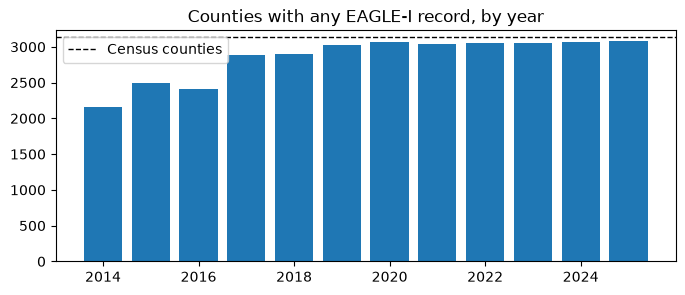

,year,counties_reported,first_ts,last_ts,pct_of_census_counties
0,2014,2152,2014-11-01 04:00:00,2014-12-31 00:00:00,68.4
1,2015,2498,2015-01-01 00:00:00,2015-12-31 00:00:00,79.5
2,2016,2405,2016-01-01 00:00:00,2016-12-31 00:00:00,76.5
3,2017,2887,2017-01-01 00:00:00,2017-12-31 00:00:00,91.8
4,2018,2895,2018-01-01 00:00:00,2018-12-31 00:00:00,92.1
5,2019,3025,2019-01-01 00:00:00,2019-12-31 00:00:00,96.2
6,2020,3072,2020-01-01 00:00:00,2020-12-31 00:00:00,97.7
7,2021,3045,2021-01-01 00:00:00,2021-12-31 00:00:00,96.9
8,2022,3057,2022-01-01 00:00:00,2022-12-31 23:45:00,97.2
9,2023,3058,2023-01-01 00:00:00,2023-12-31 23:45:00,97.3


In [17]:
# ---- 1n. County coverage per year --------------------------------------------
coverage = q("""
SELECT year, count(DISTINCT fips) AS counties_reported, min(ts) AS first_ts, max(ts) AS last_ts
FROM eaglei GROUP BY year ORDER BY year
""")
coverage["pct_of_census_counties"] = (100 * coverage["counties_reported"] / len(census)).round(1)
coverage.to_csv(TABLES / "eaglei_county_coverage_by_year.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(coverage["year"], coverage["counties_reported"])
ax.axhline(len(census), color="black", linestyle="--", linewidth=1, label="Census counties")
ax.set_title("Counties with any EAGLE-I record, by year")
ax.legend()
plt.show()
coverage

In [18]:
# ---- 1o. Snapshot grid: are any 15-minute snapshots missing? -----------------
# EAGLE-I takes a snapshot every 15 minutes. We compare the timestamps present
# against the full expected grid for each year.
grid = q("""
WITH bounds AS (
    SELECT year, min(ts) AS start_ts, (make_timestamp(year, 12, 31, 23, 45, 0)) AS end_ts
    FROM eaglei GROUP BY year
),
expected AS (
    SELECT year, unnest(generate_series(start_ts, end_ts, INTERVAL 15 MINUTE)) AS ts FROM bounds
),
present AS (SELECT DISTINCT year, ts FROM eaglei)
SELECT ex.year,
       count(*)                          AS expected_snapshots,
       count(p.ts)                       AS present_snapshots,
       count(*) - count(p.ts)            AS missing_snapshots,
       round(100 * count(p.ts) / count(*), 2) AS pct_present
FROM expected ex LEFT JOIN present p USING (year, ts)
GROUP BY ex.year ORDER BY ex.year
""")
off_grid = q("""
SELECT year, count(*) AS rows_off_15min_grid
FROM eaglei WHERE minute(ts) % 15 <> 0 OR second(ts) <> 0
GROUP BY year ORDER BY year
""")
grid = grid.merge(off_grid, on="year", how="left").fillna({"rows_off_15min_grid": 0})
grid.to_csv(TABLES / "eaglei_snapshot_grid.csv", index=False)
grid

,year,expected_snapshots,present_snapshots,missing_snapshots,pct_present,rows_off_15min_grid
0,2014,5840,5695,145,97.52,0.0
1,2015,35040,34519,521,98.51,0.0
2,2016,35136,34764,372,98.94,0.0
3,2017,35040,34702,338,99.04,1410.0
4,2018,35040,34743,297,99.15,15473.0
5,2019,35040,34902,138,99.61,132.0
6,2020,35136,35026,110,99.69,3747.0
7,2021,35040,34925,115,99.67,498.0
8,2022,35040,35037,3,99.99,0.0
9,2023,35040,35023,17,99.95,819.0


In [19]:
# ---- 1p. Longest collection gaps (consecutive missing snapshots) -------------
q("""
WITH snaps AS (
    SELECT DISTINCT ts FROM eaglei WHERE minute(ts) % 15 = 0
),
gaps AS (
    SELECT ts AS gap_after, lead(ts) OVER (ORDER BY ts) AS next_ts FROM snaps
)
SELECT gap_after, next_ts, next_ts - gap_after AS gap_length
FROM gaps WHERE next_ts - gap_after > INTERVAL 2 HOUR
ORDER BY gap_length DESC LIMIT 15
""")

,gap_after,next_ts,gap_length
0,2015-01-06 22:45:00,2015-01-07 23:15:00,1 days 00:30:00
1,2021-12-31 00:00:00,2022-01-01 00:00:00,1 days 00:00:00
2,2018-12-31 00:00:00,2019-01-01 00:00:00,1 days 00:00:00
3,2016-12-31 00:00:00,2017-01-01 00:00:00,1 days 00:00:00
4,2020-12-31 00:00:00,2021-01-01 00:00:00,1 days 00:00:00
5,2019-12-31 00:00:00,2020-01-01 00:00:00,1 days 00:00:00
6,2015-12-31 00:00:00,2016-01-01 00:00:00,1 days 00:00:00
7,2014-12-31 00:00:00,2015-01-01 00:00:00,1 days 00:00:00
8,2017-12-31 00:00:00,2018-01-01 00:00:00,1 days 00:00:00
9,2016-03-12 01:45:00,2016-03-12 19:15:00,0 days 17:30:00


In [20]:
# ---- 1q. Null customers_out: whole snapshots or scattered counties? ----------
q("""
SELECT year,
       count(*)                     AS null_rows,
       count(DISTINCT ts)           AS snapshots_with_nulls,
       count(DISTINCT fips)         AS counties_with_nulls,
       count(DISTINCT left(fips,2)) AS states_with_nulls
FROM eaglei WHERE customers_out IS NULL
GROUP BY year ORDER BY year
""")

,year,null_rows,snapshots_with_nulls,counties_with_nulls,states_with_nulls
0,2017,162648,3568,2836,51
1,2018,2027828,33760,2867,51
2,2019,1366771,31558,2991,52
3,2020,2101520,34012,3027,52
4,2021,1104738,33439,3037,53
5,2025,1972650,34078,3027,52


In [21]:
# ---- 1r. Which states hold the null customers_out rows? ----------------------
q("""
SELECT year, state, count(*) AS null_rows
FROM eaglei WHERE customers_out IS NULL
GROUP BY year, state QUALIFY row_number() OVER (PARTITION BY year ORDER BY count(*) DESC) <= 3
ORDER BY year, null_rows DESC
""")

,year,state,null_rows
0,2017,Kentucky,29400
1,2017,New Hampshire,20975
2,2017,Florida,18940
3,2018,Michigan,282913
4,2018,Texas,165182
5,2018,Missouri,117784
6,2019,Georgia,138868
7,2019,Missouri,111327
8,2019,Kansas,110016
9,2020,Nebraska,178500


In [22]:
# ---- 1s. Reporting rate per county -------------------------------------------
# Share of the year's snapshots in which a county has a row.
# Before 2022 zeros are not stored, so a low rate there mostly means "no outage".
# From 2022 zeros are stored, so a low rate means the county was not being collected.
report_rate = q("""
WITH snaps AS (SELECT year, count(DISTINCT ts) AS n_snaps FROM eaglei GROUP BY year),
county_rows AS (SELECT year, fips, count(*) AS n_rows FROM eaglei GROUP BY year, fips)
SELECT c.year,
       round(median(c.n_rows / s.n_snaps) * 100, 1)        AS median_pct_snapshots_with_row,
       round(100 * avg((c.n_rows / s.n_snaps > 0.9)::INT), 1) AS pct_counties_reporting_90pct
FROM county_rows c JOIN snaps s USING (year)
GROUP BY c.year ORDER BY c.year
""")
report_rate

,year,median_pct_snapshots_with_row,pct_counties_reporting_90pct
0,2014,7.0,0.8
1,2015,9.0,0.4
2,2016,9.4,0.5
3,2017,8.9,0.5
4,2018,15.7,1.0
5,2019,16.9,1.0
6,2020,17.9,0.9
7,2021,16.6,1.4
8,2022,17.8,1.6
9,2023,18.5,1.6


In [23]:
# =============================================================================
# 2. NOAA STORM EVENTS (details)
# =============================================================================
# ---- 2a. Shape, columns, sample ----------------------------------------------
print(q("SELECT count(*) AS rows, count(DISTINCT EVENT_ID) AS events, count(DISTINCT EPISODE_ID) AS episodes FROM storms_raw"))
q("SELECT * FROM storms_raw USING SAMPLE 3 ROWS")

     rows  events  episodes
0  771302  771302    118189


,SOURCE_YEAR,BEGIN_YEARMONTH,BEGIN_DAY,BEGIN_TIME,END_YEARMONTH,END_DAY,END_TIME,EPISODE_ID,EVENT_ID,STATE,STATE_FIPS,YEAR,MONTH_NAME,EVENT_TYPE,CZ_TYPE,...,TOR_OTHER_CZ_FIPS,TOR_OTHER_CZ_NAME,BEGIN_RANGE,BEGIN_AZIMUTH,BEGIN_LOCATION,END_RANGE,END_AZIMUTH,END_LOCATION,BEGIN_LAT,BEGIN_LON,END_LAT,END_LON,EPISODE_NARRATIVE,EVENT_NARRATIVE,DATA_SOURCE
0,2014,201410,1,0,201410,31,2359,90052,542380,CALIFORNIA,6,2014,October,Drought,Z,...,None,None,None,None,None,None,None,None,None,None,None,None,The California drought continued in full force...,NaN,CSV
1,2015,201512,14,800,201512,15,1430,110457,664246,COLORADO,8,2015,December,Heavy Snow,Z,...,None,None,None,None,None,None,None,None,None,None,None,None,A vigorous Pacific trough produced significant...,Snowfall amounts of 5 to 12 inches were measur...,CSV
2,2016,201601,12,900,201601,12,1600,103059,615769,OHIO,39,2016,January,Winter Weather,Z,...,None,None,None,None,None,None,None,None,None,None,None,None,An arctic cold front passed east through the r...,A half of snow was measured northeast of Hamil...,CSV


In [24]:
# ---- 2b. Null % for every column ---------------------------------------------
storm_cols = q("DESCRIBE storms_raw")["column_name"].tolist()
null_sql = ", ".join(f"round(100 * avg(({c} IS NULL)::INT), 2) AS \"{c}\"" for c in storm_cols)
storm_nulls = q(f"SELECT {null_sql} FROM storms_raw").T.rename(columns={0: "pct_null_all_rows"})

# Some columns only apply to certain events (e.g. tornado width only for tornadoes).
# For those we also measure nulls inside the rows where the column applies.
APPLIES_TO = {
    "MAGNITUDE":          "EVENT_TYPE IN ('Thunderstorm Wind','Hail','High Wind','Strong Wind','Marine Thunderstorm Wind','Marine High Wind','Marine Hail','Marine Strong Wind')",
    "MAGNITUDE_TYPE":     "EVENT_TYPE IN ('Thunderstorm Wind','High Wind','Strong Wind','Marine Thunderstorm Wind','Marine High Wind','Marine Strong Wind')",
    "TOR_F_SCALE":        "EVENT_TYPE = 'Tornado'",
    "TOR_LENGTH":         "EVENT_TYPE = 'Tornado'",
    "TOR_WIDTH":          "EVENT_TYPE = 'Tornado'",
    "TOR_OTHER_WFO":      "EVENT_TYPE = 'Tornado'",
    "TOR_OTHER_CZ_STATE": "EVENT_TYPE = 'Tornado'",
    "TOR_OTHER_CZ_FIPS":  "EVENT_TYPE = 'Tornado'",
    "TOR_OTHER_CZ_NAME":  "EVENT_TYPE = 'Tornado'",
    "FLOOD_CAUSE":        "EVENT_TYPE IN ('Flood','Flash Flood','Debris Flow')",
    "CATEGORY":           "EVENT_TYPE = 'Hurricane (Typhoon)'",
    "BEGIN_RANGE":        "CZ_TYPE = 'C'",
    "BEGIN_AZIMUTH":      "CZ_TYPE = 'C'",
    "BEGIN_LOCATION":     "CZ_TYPE = 'C'",
    "END_RANGE":          "CZ_TYPE = 'C'",
    "END_AZIMUTH":        "CZ_TYPE = 'C'",
    "END_LOCATION":       "CZ_TYPE = 'C'",
    "BEGIN_LAT":          "CZ_TYPE = 'C'",
    "BEGIN_LON":          "CZ_TYPE = 'C'",
    "END_LAT":            "CZ_TYPE = 'C'",
    "END_LON":            "CZ_TYPE = 'C'",
}
storm_nulls["applies_to"] = pd.Series(APPLIES_TO)
storm_nulls["pct_null_where_applies"] = [
    q(f"SELECT round(100 * avg(({c} IS NULL)::INT), 2) FROM storms_raw WHERE {APPLIES_TO[c]}").iat[0, 0]
    if c in APPLIES_TO else storm_nulls.loc[c, "pct_null_all_rows"]
    for c in storm_nulls.index
]
storm_nulls["drop_candidate"] = storm_nulls["pct_null_where_applies"] > NULL_CUTOFF
storm_nulls.to_csv(TABLES / "storm_null_rates.csv")
storm_nulls.sort_values("pct_null_where_applies", ascending=False)

,pct_null_all_rows,applies_to,pct_null_where_applies,drop_candidate
TOR_OTHER_CZ_FIPS,99.69,EVENT_TYPE = 'Tornado',86.43,True
TOR_OTHER_CZ_NAME,99.69,EVENT_TYPE = 'Tornado',86.43,True
TOR_OTHER_CZ_STATE,99.69,EVENT_TYPE = 'Tornado',86.42,True
TOR_OTHER_WFO,99.69,EVENT_TYPE = 'Tornado',86.42,True
DAMAGE_PROPERTY,20.62,NaN,20.62,False
DAMAGE_CROPS,20.48,NaN,20.48,False
EVENT_NARRATIVE,20.25,NaN,20.25,False
END_AZIMUTH,38.89,CZ_TYPE = 'C',0.04,False
BEGIN_AZIMUTH,38.89,CZ_TYPE = 'C',0.04,False
BEGIN_LOCATION,38.89,CZ_TYPE = 'C',0.04,False


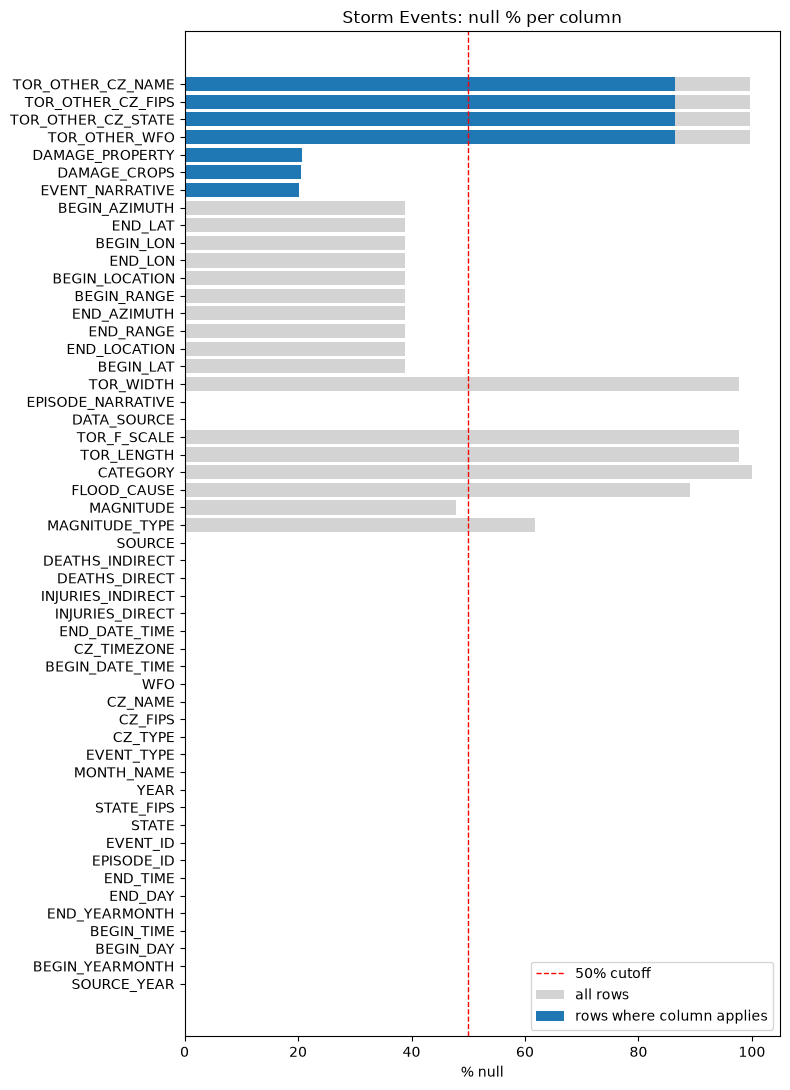

In [25]:
# ---- 2c. Null % chart --------------------------------------------------------
plot_df = storm_nulls.sort_values("pct_null_where_applies")
fig, ax = plt.subplots(figsize=(8, 11))
ax.barh(plot_df.index, plot_df["pct_null_all_rows"], color="lightgray", label="all rows")
ax.barh(plot_df.index, plot_df["pct_null_where_applies"], color="tab:blue", label="rows where column applies")
ax.axvline(NULL_CUTOFF, color="red", linestyle="--", linewidth=1, label=f"{NULL_CUTOFF}% cutoff")
ax.set_xlabel("% null")
ax.set_title("Storm Events: null % per column")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [26]:
# ---- 2d. Type conversion checks ----------------------------------------------
# Damage is stored as text like "10.00K"; times as "18-FEB-14 10:00:00" in local standard time.
q("""
SELECT
    sum((TRY_STRPTIME(BEGIN_DATE_TIME, '%d-%b-%y %H:%M:%S') IS NULL)::INT) AS bad_begin_time,
    sum((TRY_STRPTIME(END_DATE_TIME,   '%d-%b-%y %H:%M:%S') IS NULL)::INT) AS bad_end_time,
    sum((MAGNITUDE IS NOT NULL AND TRY_CAST(MAGNITUDE AS DOUBLE) IS NULL)::INT) AS bad_magnitude,
    sum((BEGIN_LAT IS NOT NULL AND TRY_CAST(BEGIN_LAT AS DOUBLE) IS NULL)::INT) AS bad_lat,
    sum((DAMAGE_PROPERTY IS NOT NULL AND NOT regexp_full_match(DAMAGE_PROPERTY, '[0-9.]+[KMB]?'))::INT) AS bad_damage,
    sum((STRPTIME(END_DATE_TIME, '%d-%b-%y %H:%M:%S') < STRPTIME(BEGIN_DATE_TIME, '%d-%b-%y %H:%M:%S'))::INT) AS end_before_begin
FROM storms_raw
""")

,bad_begin_time,bad_end_time,bad_magnitude,bad_lat,bad_damage,end_before_begin
0,0.0,0.0,0.0,0.0,0.0,0.0


In [27]:
# ---- 2e. Damage suffixes (K = thousand, M = million, B = billion) -----------
q("SELECT regexp_extract(DAMAGE_PROPERTY, '[A-Z]$') AS suffix, count(*) AS rows FROM storms_raw GROUP BY 1 ORDER BY 2 DESC")

,suffix,rows
0,K,607769
1,NaN,159050
2,M,4316
3,,122
4,B,45


In [28]:
# ---- 2f. Time zones: needed to convert local times to UTC (EAGLE-I is UTC) ---
q("SELECT CZ_TIMEZONE, count(*) AS rows FROM storms_raw GROUP BY 1 ORDER BY 2 DESC")

,CZ_TIMEZONE,rows
0,CST-6,355148
1,EST-5,266069
2,MST-7,96042
3,PST-8,40146
4,HST-10,6843
5,AST-4,3262
6,AKST-9,2867
7,SST-11,293
8,PDT-7,290
9,GST10,275


In [29]:
# ---- 2g. Typed storm view ----------------------------------------------------
# UTC = local time minus the offset in CZ_TIMEZONE (e.g. 'CST-6' -> +6 hours)
con.execute("""
CREATE OR REPLACE VIEW storms AS
SELECT
    CAST(EVENT_ID AS BIGINT)                           AS event_id,
    CAST(EPISODE_ID AS BIGINT)                         AS episode_id,
    CAST(SOURCE_YEAR AS INT)                           AS year,
    EVENT_TYPE                                         AS event_type,
    CZ_TYPE                                            AS cz_type,
    lpad(STATE_FIPS, 2, '0')                           AS state_fips,
    lpad(CZ_FIPS, 3, '0')                              AS cz_fips,
    lpad(STATE_FIPS, 2, '0') || lpad(CZ_FIPS, 3, '0')  AS cz_code,
    STRPTIME(BEGIN_DATE_TIME, '%d-%b-%y %H:%M:%S')
        - to_hours(CAST(regexp_extract(CZ_TIMEZONE, '(-?[0-9]+)$', 1) AS INT)) AS begin_utc,
    STRPTIME(END_DATE_TIME, '%d-%b-%y %H:%M:%S')
        - to_hours(CAST(regexp_extract(CZ_TIMEZONE, '(-?[0-9]+)$', 1) AS INT)) AS end_utc,
    TRY_CAST(MAGNITUDE AS DOUBLE)                      AS magnitude,
    MAGNITUDE_TYPE                                     AS magnitude_type,
    TOR_F_SCALE                                        AS tor_f_scale,
    TRY_CAST(TOR_LENGTH AS DOUBLE)                     AS tor_length,
    TRY_CAST(TOR_WIDTH AS DOUBLE)                      AS tor_width,
    TRY_CAST(CATEGORY AS INT)                          AS hurricane_category,
    TRY_CAST(BEGIN_LAT AS DOUBLE)                      AS begin_lat,
    TRY_CAST(BEGIN_LON AS DOUBLE)                      AS begin_lon,
    TRY_CAST(regexp_extract(DAMAGE_PROPERTY, '([0-9.]+)', 1) AS DOUBLE)
        * CASE regexp_extract(DAMAGE_PROPERTY, '([KMB])$', 1)
              WHEN 'K' THEN 1e3 WHEN 'M' THEN 1e6 WHEN 'B' THEN 1e9 ELSE 1 END AS damage_property_usd
FROM storms_raw
""")
q("SELECT * FROM storms USING SAMPLE 5 ROWS")

,event_id,episode_id,year,event_type,cz_type,state_fips,cz_fips,cz_code,begin_utc,end_utc,magnitude,magnitude_type,tor_f_scale,tor_length,tor_width,hurricane_category,begin_lat,begin_lon,damage_property_usd
0,712156,118181,2017,Flood,C,44,003,44003,2017-07-12 20:55:00,2017-07-12 23:00:00,NaN,NaN,None,NaN,NaN,<NA>,41.6468,-71.6921,0.0
1,685554,114390,2017,High Wind,Z,56,110,56110,2017-02-10 11:30:00,2017-02-10 12:30:00,35.0,MS,None,NaN,NaN,<NA>,NaN,NaN,0.0
2,981629,162591,2021,Flood,C,18,141,18141,2021-08-25 01:08:00,2021-08-25 01:15:00,NaN,NaN,None,NaN,NaN,<NA>,41.6600,-86.2700,0.0
3,974913,161434,2021,Heat,Z,17,080,17080,2021-08-09 17:00:00,2021-08-13 00:00:00,NaN,NaN,None,NaN,NaN,<NA>,NaN,NaN,0.0
4,1162591,188705,2023,Thunderstorm Wind,C,39,123,39123,2023-08-25 03:18:00,2023-08-25 03:18:00,55.0,EG,None,NaN,NaN,<NA>,41.6500,-82.8200,0.0


In [30]:
# ---- 2h. Duration sanity check -----------------------------------------------
q("""
SELECT event_type,
       count(*) AS events,
       round(median(date_diff('minute', begin_utc, end_utc)) / 60, 1) AS median_hours,
       round(max(date_diff('minute', begin_utc, end_utc)) / 60, 1)    AS max_hours
FROM storms GROUP BY event_type ORDER BY events DESC LIMIT 15
""")

,event_type,events,median_hours,max_hours
0,Thunderstorm Wind,209029,0.0,480.1
1,Hail,107058,0.0,480.1
2,Flash Flood,49149,2.0,672.0
3,Winter Weather,45427,12.0,264.0
4,High Wind,44413,2.3,529.8
5,Drought,37092,720.0,744.0
6,Winter Storm,35212,19.3,242.0
7,Flood,32714,5.3,744.0
8,Marine Thunderstorm Wind,27428,0.0,2.0
9,Heavy Snow,26492,19.0,444.0


In [31]:
# ---- 2i. County-coded (C) vs forecast-zone-coded (Z) vs marine events -------
# Zone codes are NOT county FIPS. They must go through the NWS zone->county crosswalk.
cz_mix = q("""
SELECT year,
       count(*) AS events,
       round(100 * avg((cz_type = 'C')::INT), 1) AS pct_county,
       round(100 * avg((cz_type = 'Z')::INT), 1) AS pct_zone,
       round(100 * avg((event_type LIKE 'Marine%' OR event_type IN ('Waterspout'))::INT), 1) AS pct_marine
FROM storms GROUP BY year ORDER BY year
""")
cz_mix

,year,events,pct_county,pct_zone,pct_marine
0,2014,59475,54.7,45.3,3.0
1,2015,57907,60.6,39.4,3.8
2,2016,56005,60.7,39.3,4.4
3,2017,57041,64.8,35.2,4.4
4,2018,62699,57.0,43.0,3.8
5,2019,67864,60.0,40.0,4.2
6,2020,61281,59.7,40.3,5.5
7,2021,61389,52.4,47.6,5.0
8,2022,69887,47.1,52.9,4.3
9,2023,75593,56.2,43.8,4.0


In [32]:
# ---- 2j. Event types and how each is located --------------------------------
event_types = q("""
SELECT event_type,
       count(*)                                  AS events,
       round(100 * avg((cz_type = 'C')::INT), 0) AS pct_county_coded,
       round(100 * avg((magnitude IS NOT NULL)::INT), 0) AS pct_with_magnitude,
       round(100 * avg((damage_property_usd > 0)::INT), 1) AS pct_with_damage
FROM storms GROUP BY event_type ORDER BY events DESC
""")
event_types.to_csv(TABLES / "storm_event_types.csv", index=False)
event_types

,event_type,events,pct_county_coded,pct_with_magnitude,pct_with_damage
0,Thunderstorm Wind,209029,100.0,100.0,53.4
1,Hail,107058,100.0,100.0,8.5
2,Flash Flood,49149,100.0,0.0,33.7
3,Winter Weather,45427,0.0,0.0,3.2
4,High Wind,44413,0.0,100.0,13.1
5,Drought,37092,0.0,0.0,0.7
6,Winter Storm,35212,0.0,0.0,6.8
7,Flood,32714,100.0,0.0,22.9
8,Marine Thunderstorm Wind,27428,0.0,100.0,0.2
9,Heavy Snow,26492,0.0,0.0,2.4


In [33]:
# ---- 2k. County-coded events: valid FIPS? ------------------------------------
q("""
SELECT
    count(*)                               AS county_coded_events,
    sum((c.fips IS NULL)::INT)             AS fips_not_in_census,
    round(100 * avg((c.fips IS NULL)::INT), 2) AS pct_not_in_census
FROM storms s LEFT JOIN census c ON c.fips = s.cz_code
WHERE s.cz_type = 'C'
""")

,county_coded_events,fips_not_in_census,pct_not_in_census
0,440627,4719.0,1.07


In [34]:
# ---- 2l. Zone-coded events: can the crosswalk map them to counties? ---------
# Use the crosswalk version that was in effect on the event's date.
zone_map = q("""
WITH z AS (
    SELECT s.event_id, s.year, s.event_type, r.abbr || s.cz_fips AS state_zone, CAST(s.begin_utc AS DATE) AS d
    FROM storms s JOIN regions r USING (state_fips)
    WHERE s.cz_type = 'Z'
),
matched AS (
    SELECT z.event_id, count(DISTINCT x.county_fips) AS n_counties
    FROM z JOIN crosswalk x
      ON x.state_zone = z.state_zone
     AND z.d >= CAST(x.effective_date AS DATE)
     AND (x.next_effective_date IS NULL OR z.d < CAST(x.next_effective_date AS DATE))
    GROUP BY z.event_id
)
SELECT z.year,
       count(*)                                      AS zone_events,
       round(100 * avg((m.event_id IS NOT NULL)::INT), 1) AS pct_mapped,
       round(avg(m.n_counties), 2)                   AS avg_counties_per_zone_event
FROM z LEFT JOIN matched m USING (event_id)
GROUP BY z.year ORDER BY z.year
""")
zone_map

,year,zone_events,pct_mapped,avg_counties_per_zone_event
0,2014,25103,99.7,1.27
1,2015,20565,99.8,1.29
2,2016,19478,99.6,1.30
3,2017,17552,99.6,1.37
4,2018,24507,99.7,1.31
5,2019,24280,99.4,1.32
6,2020,21242,99.8,1.35
7,2021,26054,99.9,1.34
8,2022,33898,99.9,1.27
9,2023,29991,99.9,1.25


In [35]:
# ---- 2m. Which zone events fail to map? -------------------------------------
q("""
WITH z AS (
    SELECT s.event_id, s.event_type, s.state_fips, r.abbr || s.cz_fips AS state_zone, CAST(s.begin_utc AS DATE) AS d
    FROM storms s LEFT JOIN regions r USING (state_fips)
    WHERE s.cz_type = 'Z'
)
SELECT event_type, count(*) AS unmapped
FROM z
WHERE NOT EXISTS (
    SELECT 1 FROM crosswalk x
    WHERE x.state_zone = z.state_zone
      AND z.d >= CAST(x.effective_date AS DATE)
      AND (x.next_effective_date IS NULL OR z.d < CAST(x.next_effective_date AS DATE)))
GROUP BY event_type ORDER BY unmapped DESC LIMIT 10
""")

,event_type,unmapped
0,Marine Thunderstorm Wind,27428
1,Waterspout,2368
2,Marine High Wind,711
3,Marine Tropical Storm,592
4,Marine Hail,312
5,Drought,256
6,Excessive Heat,211
7,Winter Storm,186
8,Rip Current,174
9,Coastal Flood,125


In [36]:
# =============================================================================
# 3. SUPPORTING FILES: MCC, Census population, DQI, coverage history
# =============================================================================
# ---- 3a. MCC customers vs Census population (is population a usable proxy?) -
mcc_pop = mcc.merge(census, on="fips", how="outer", indicator=True)
print(mcc_pop["_merge"].value_counts())
both = mcc_pop[mcc_pop["_merge"] == "both"]
print("correlation MCC vs population:", round(both["mcc_customers"].corr(both["pop2023"]), 3))
print("median customers per person:", round((both["mcc_customers"] / both["pop2023"]).median(), 3))
mcc_pop[mcc_pop["_merge"] != "both"].head(15)

_merge
both          3120
left_only      114
right_only      24
Name: count, dtype: int64
correlation MCC vs population: 0.971
median customers per person: 0.508


,fips,mcc_customers,STNAME,CTYNAME,pop2023,_merge
67,02013,NaN,Alaska,Aleutians East Borough,3461.0,right_only
71,02060,NaN,Alaska,Bristol Bay Borough,844.0,right_only
72,02063,NaN,Alaska,Chugach Census Area,6769.0,right_only
73,02066,NaN,Alaska,Copper River Census Area,2674.0,right_only
84,02164,NaN,Alaska,Lake and Peninsula Borough,1331.0,right_only
94,02261,5469.0,NaN,NaN,NaN,left_only
240,06105,NaN,California,Trinity County,15670.0,right_only
310,09001,310526.0,NaN,NaN,NaN,left_only
311,09003,572922.0,NaN,NaN,NaN,left_only
312,09005,102535.0,NaN,NaN,NaN,left_only


In [37]:
# ---- 3b. DQI (Data Quality Index) by FEMA region and year -------------------
dqi = pd.read_csv(DQI_CSV)
dqi_wide = dqi.pivot(index="fema", columns="year", values="DQI").round(1)
dqi_wide.to_csv(TABLES / "dqi_by_fema_region.csv")
dqi_wide

year,2018,2019,2020,2021,2022
fema,,,,,
1,70.3,90.1,61.8,94.0,93.7
2,82.4,84.9,85.8,87.3,93.5
3,91.4,91.7,84.9,93.0,88.5
4,74.7,65.0,77.5,85.2,79.2
5,72.8,82.0,83.9,87.3,87.6
6,78.9,76.2,64.7,80.6,87.6
7,63.3,50.3,77.2,84.0,79.9
8,59.0,61.7,66.7,73.2,80.9
9,39.4,69.9,71.6,80.3,87.4


In [38]:
# ---- 3c. Coverage history: % of customers EAGLE-I tracks, by state ----------
cov = pd.read_csv(COVERAGE_CSV)
cov["year"] = pd.to_datetime(cov["year"], format="%m/%d/%y").dt.year
cov["fema_region"] = cov["state"].map(abbr_to_region)
cov_region = cov.groupby(["fema_region", "year"])["max_pct_covered"].mean().unstack().round(2)
cov_region

year,2018,2019,2020,2021,2022
fema_region,,,,,
1,0.94,0.96,0.97,0.98,0.98
2,0.74,0.74,0.74,1.00,1.00
3,0.96,0.96,0.96,0.96,0.97
4,0.81,0.86,0.87,0.88,0.88
5,0.85,0.88,0.89,0.90,0.90
6,0.84,0.87,0.83,0.89,0.89
7,0.71,0.76,0.78,0.78,0.73
8,0.57,0.74,0.76,0.76,0.78
9,0.48,0.49,0.50,0.55,0.55


In [39]:
# ---- 3d. States with the lowest coverage (latest year available) ------------
cov[cov["year"] == cov["year"].max()].sort_values("max_pct_covered").head(10)

,year,state,total_customers,min_covered,max_covered,min_pct_covered,max_pct_covered,fema_region
19,2022,AS,12216,0,0,0.00,0.00,9
64,2022,GU,51938,0,0,0.00,0.00,9
139,2022,MP,15541,0,0,0.00,0.00,9
164,2022,NE,1034499,496518,496518,0.48,0.48,7
94,2022,KS,1980177,1138929,1171642,0.58,0.59,7
159,2022,ND,463692,298846,307185,0.64,0.66,8
279,2022,WY,329909,232248,232954,0.70,0.71,8
4,2022,AK,364614,226079,258830,0.62,0.71,10
234,2022,TN,3433064,2454449,2578021,0.71,0.75,4
149,2022,MT,634592,478148,484486,0.75,0.76,8


In [40]:
# =============================================================================
# 4. REGION COMPARISON: Southeast (FEMA IV) vs the rest
# =============================================================================
county_region = census.assign(state_fips=census["fips"].str[:2]).merge(regions, on="state_fips")
con.register("county_region", county_region)

region_eaglei = q("""
WITH snaps AS (SELECT count(DISTINCT ts) AS n FROM eaglei WHERE year = 2023),
c23 AS (SELECT fips, count(*) AS n_rows FROM eaglei WHERE year = 2023 GROUP BY fips)
SELECT cr.fema_region,
       count(*)                                         AS census_counties,
       count(c23.fips)                                  AS counties_in_eaglei_2023,
       round(100 * count(c23.fips) / count(*), 1)       AS pct_counties_covered,
       round(100 * median(c23.n_rows / (SELECT n FROM snaps)), 1) AS median_pct_snapshots_reported_2023
FROM county_region cr LEFT JOIN c23 USING (fips)
GROUP BY cr.fema_region ORDER BY cr.fema_region
""")
region_storms = q("""
SELECT r.fema_region,
       count(*)                                  AS storm_events,
       round(100 * avg((s.cz_type = 'C')::INT), 1) AS pct_county_coded
FROM storms s JOIN regions r USING (state_fips)
GROUP BY r.fema_region ORDER BY r.fema_region
""")
region_cmp = (region_eaglei
              .merge(region_storms, on="fema_region")
              .merge(dqi_wide[[2022]].rename(columns={2022: "dqi_2022"}), left_on="fema_region", right_index=True)
              .merge(cov_region[[2022]].rename(columns={2022: "pct_customers_tracked_2022"}),
                     left_on="fema_region", right_index=True))
region_cmp["is_southeast"] = region_cmp["fema_region"] == 4
region_cmp.to_csv(TABLES / "region_comparison.csv", index=False)
region_cmp

,fema_region,census_counties,counties_in_eaglei_2023,pct_counties_covered,median_pct_snapshots_reported_2023,storm_events,pct_county_coded,dqi_2022,pct_customers_tracked_2022,is_southeast
0,1,68,59,86.8,22.8,22711,46.8,93.7,0.98,False
1,2,83,83,100.0,34.5,32625,55.7,93.5,1.00,False
2,3,283,283,100.0,24.2,72984,66.6,88.5,0.97,False
3,4,736,727,98.8,22.2,131081,73.0,79.2,0.88,True
4,5,524,523,99.8,15.7,101619,61.4,87.6,0.90,False
5,6,503,500,99.4,22.2,122275,58.4,87.6,0.89,False
6,7,412,368,89.3,10.1,99346,70.5,79.9,0.73,False
7,8,291,283,97.3,6.0,89351,45.3,80.9,0.78,False
8,9,95,93,97.9,46.4,46594,35.0,87.4,0.55,False
9,10,149,121,81.2,10.9,17324,23.1,85.6,0.85,False


In [41]:
# ---- 4b. Share of all records that fall in the Southeast ---------------------
q("""
SELECT r.is_southeast, count(*) AS eaglei_rows, round(100 * count(*) / sum(count(*)) OVER (), 1) AS pct_rows
FROM eaglei e JOIN regions r ON r.state_fips = left(e.fips, 2)
GROUP BY r.is_southeast
""")

,is_southeast,eaglei_rows,pct_rows
0,False,184598928,74.0
1,True,64717615,26.0


In [42]:
# =============================================================================
# 5. SIGNAL CHECK: do storms line up with outages? (2022-2025, zeros are stored)
# =============================================================================
# For each county-coded storm, take the worst hour of outages in the 24 h after it starts.
# Baseline = the same county and hours exactly one week earlier.
con.execute("""
CREATE OR REPLACE TEMP TABLE eaglei_hourly AS
SELECT fips, date_trunc('hour', ts) AS hr, max(customers_out) AS max_out
FROM eaglei WHERE year >= 2022 AND customers_out IS NOT NULL
GROUP BY fips, hr
""")

signal = q("""
WITH ev AS (
    SELECT event_id, event_type, cz_code AS fips, date_trunc('hour', begin_utc) AS start_hr
    FROM storms WHERE cz_type = 'C' AND year >= 2022
),
windows AS (
    SELECT ev.*, unnest(range(0, 24)) AS h FROM ev
),
after AS (
    SELECT w.event_id, any_value(w.event_type) AS event_type, any_value(w.fips) AS fips,
           max(a.max_out) AS peak_after, count(a.hr) AS hours_with_data,
           max(b.max_out) AS peak_week_before
    FROM windows w
    LEFT JOIN eaglei_hourly a ON a.fips = w.fips AND a.hr = w.start_hr + to_hours(w.h)
    LEFT JOIN eaglei_hourly b ON b.fips = w.fips AND b.hr = w.start_hr + to_hours(w.h) - INTERVAL 7 DAY
    GROUP BY w.event_id
)
SELECT a.*, m.mcc_customers,
       a.peak_after / m.mcc_customers       AS peak_pct_after,
       a.peak_week_before / m.mcc_customers AS peak_pct_week_before
FROM after a LEFT JOIN mcc m USING (fips)
""")
print("events:", len(signal), "| with no EAGLE-I data in window:", (signal["hours_with_data"] == 0).sum())

signal_summary = (signal[signal["hours_with_data"] > 0]
                  .groupby("event_type")
                  .agg(events=("event_id", "count"),
                       pct_peak_ge_1pct=("peak_pct_after", lambda s: round(100 * (s >= 0.01).mean(), 1)),
                       pct_baseline_ge_1pct=("peak_pct_week_before", lambda s: round(100 * (s >= 0.01).mean(), 1)),
                       median_peak_pct=("peak_pct_after", lambda s: round(100 * s.median(), 2)))
                  .sort_values("events", ascending=False))
signal_summary.to_csv(TABLES / "storm_outage_signal.csv")
signal_summary

events: 156810 | with no EAGLE-I data in window: 14668


,events,pct_peak_ge_1pct,pct_baseline_ge_1pct,median_peak_pct
event_type,,,,
Thunderstorm Wind,75036,71.0,12.1,3.10
Hail,32341,44.2,9.5,0.69
Flash Flood,15299,48.5,14.6,0.94
Flood,8174,36.6,13.0,0.47
Tornado,6074,70.7,9.0,4.00
Heavy Rain,3111,32.0,8.7,0.41
Lightning,931,46.2,13.2,0.84
Funnel Cloud,738,30.5,8.7,0.25
Debris Flow,361,33.8,14.4,0.44


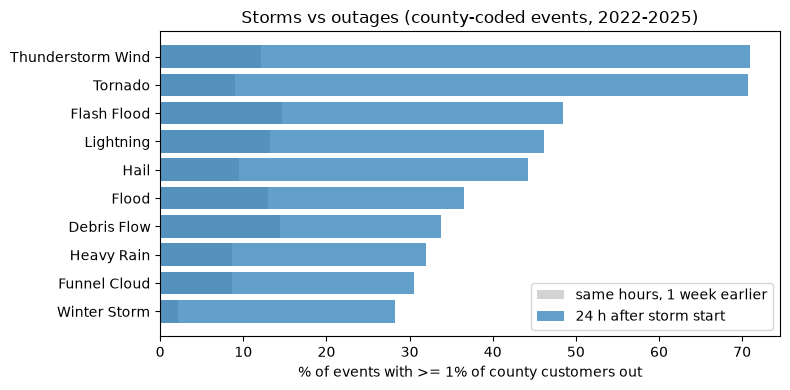

In [43]:
# ---- 5b. Signal chart --------------------------------------------------------
top = signal_summary.head(10).sort_values("pct_peak_ge_1pct")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top.index, top["pct_baseline_ge_1pct"], color="lightgray", label="same hours, 1 week earlier")
ax.barh(top.index, top["pct_peak_ge_1pct"], color="tab:blue", alpha=0.7, label="24 h after storm start")
ax.set_xlabel("% of events with >= 1% of county customers out")
ax.set_title("Storms vs outages (county-coded events, 2022-2025)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [44]:
# =============================================================================
# 6. TRAIN / VALIDATION / TEST READINESS (train 2014-2023, val 2024, test 2025)
# =============================================================================
split = (coverage[["year", "counties_reported"]]
         .merge(grid[["year", "pct_present"]], on="year")
         .merge(eaglei_nulls[["year", "pct_null_customers_out", "pct_null_total_customers"]], on="year")
         .merge(cz_mix[["year", "events", "pct_county"]].rename(columns={"events": "storm_events"}), on="year")
         .merge(zone_map[["year", "pct_mapped"]].rename(columns={"pct_mapped": "pct_zone_events_mapped"}), on="year"))
split["zeros_stored"] = split["year"] >= 2022
split["split"] = pd.cut(split["year"], [2013, 2023, 2024, 2025], labels=["train", "validation", "test"])
split.to_csv(TABLES / "split_readiness.csv", index=False)
split

,year,counties_reported,pct_present,pct_null_customers_out,pct_null_total_customers,storm_events,pct_county,pct_zone_events_mapped,zeros_stored,split
0,2014,2152,97.52,0.00,100.0,59475,54.7,99.7,False,train
1,2015,2498,98.51,0.00,100.0,57907,60.6,99.8,False,train
2,2016,2405,98.94,0.00,100.0,56005,60.7,99.6,False,train
3,2017,2887,99.04,1.08,100.0,57041,64.8,99.6,False,train
4,2018,2895,99.15,9.31,100.0,62699,57.0,99.7,False,train
5,2019,3025,99.61,5.68,100.0,67864,60.0,99.4,False,train
6,2020,3072,99.69,8.23,100.0,61281,59.7,99.8,False,train
7,2021,3045,99.67,4.45,100.0,61389,52.4,99.9,False,train
8,2022,3057,99.99,0.00,100.0,69887,47.1,99.9,True,train
9,2023,3058,99.95,0.00,100.0,75593,56.2,99.9,True,train


In [45]:
# =============================================================================
# 7. COLUMN RELEVANCE TAGS (for the modeling goal)
# =============================================================================
# leakage = only known after the storm has happened, so it cannot be a model input
RELEVANCE = {
    # EAGLE-I
    "fips_code": "location", "county": "location", "state": "location",
    "customers_out": "outage target", "total_customers": "outage target (denominator)",
    "run_start_time": "time", "SOURCE_YEAR": "time",
    # Storm Events: time / id
    "BEGIN_YEARMONTH": "time", "BEGIN_DAY": "time", "BEGIN_TIME": "time", "END_YEARMONTH": "time",
    "END_DAY": "time", "END_TIME": "time", "BEGIN_DATE_TIME": "time", "END_DATE_TIME": "time",
    "CZ_TIMEZONE": "time", "YEAR": "time", "MONTH_NAME": "time",
    "EPISODE_ID": "id", "EVENT_ID": "id", "DATA_SOURCE": "id",
    # Storm Events: location
    "STATE": "location", "STATE_FIPS": "location", "CZ_TYPE": "location", "CZ_FIPS": "location",
    "CZ_NAME": "location", "WFO": "location", "BEGIN_LAT": "location", "BEGIN_LON": "location",
    "END_LAT": "location", "END_LON": "location", "BEGIN_RANGE": "location", "BEGIN_AZIMUTH": "location",
    "BEGIN_LOCATION": "location", "END_RANGE": "location", "END_AZIMUTH": "location", "END_LOCATION": "location",
    "TOR_OTHER_WFO": "location", "TOR_OTHER_CZ_STATE": "location", "TOR_OTHER_CZ_FIPS": "location",
    "TOR_OTHER_CZ_NAME": "location",
    # Storm Events: storm description. These are OBSERVED values; at prediction time
    # they must come from a forecast/alert instead (observed = stand-in for forecast).
    "EVENT_TYPE": "storm (observed)", "MAGNITUDE": "storm (observed)", "MAGNITUDE_TYPE": "storm (observed)",
    "CATEGORY": "storm (observed)", "FLOOD_CAUSE": "storm (observed)",
    # Storm Events: measured after the fact
    "TOR_F_SCALE": "leakage (rated after survey)", "TOR_LENGTH": "leakage (measured after)",
    "TOR_WIDTH": "leakage (measured after)", "SOURCE": "leakage (report source)",
    "INJURIES_DIRECT": "leakage", "INJURIES_INDIRECT": "leakage", "DEATHS_DIRECT": "leakage",
    "DEATHS_INDIRECT": "leakage", "DAMAGE_PROPERTY": "leakage", "DAMAGE_CROPS": "leakage",
    "EPISODE_NARRATIVE": "leakage (free text)", "EVENT_NARRATIVE": "leakage (free text)",
}
tags = pd.DataFrame({"column": list(RELEVANCE), "tag": list(RELEVANCE.values())})
tags = tags.merge(storm_nulls[["pct_null_all_rows", "pct_null_where_applies", "drop_candidate"]],
                  left_on="column", right_index=True, how="left")
tags.to_csv(TABLES / "column_tags.csv", index=False)
print("untagged storm columns:", sorted(set(storm_cols) - set(RELEVANCE)))
tags

untagged storm columns: []


,column,tag,pct_null_all_rows,pct_null_where_applies,drop_candidate
0,fips_code,location,NaN,NaN,NaN
1,county,location,NaN,NaN,NaN
2,state,location,NaN,NaN,NaN
3,customers_out,outage target,NaN,NaN,NaN
4,total_customers,outage target (denominator),NaN,NaN,NaN
5,run_start_time,time,NaN,NaN,NaN
6,SOURCE_YEAR,time,0.00,0.00,False
7,BEGIN_YEARMONTH,time,0.00,0.00,False
8,BEGIN_DAY,time,0.00,0.00,False
9,BEGIN_TIME,time,0.00,0.00,False


In [46]:
con.close()